# Student Score Prediction (Regression)

This notebook builds regression models to predict student final scores using the EWS feature store. We compare Ridge and Random Forest regressors across different weeks to understand how prediction accuracy improves as more behavioral data becomes available.

---

## 1. Setup & Imports <a id="1-setup"></a>

In [16]:
%reset -f

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Libraries loaded.")

Libraries loaded.


---

## 2. Load Data <a id="2-load"></a>

Load the engineered feature store containing weekly snapshots of student engagement, assessments, and demographics.

In [18]:
from pathlib import Path
import pandas as pd

ROOT = Path("..")  # script directory
# If script is in a subfolder, use parents[1] or [2] to reach repo root
FIG_DIR = ROOT / "reports" / "figures"
FI_DIR = FIG_DIR / "feature_importance"
GAINS_DIR = ROOT / "reports" / "feature_importance_gains"
PROC_DIR = ROOT / "data" / "processed"

FI_DIR.mkdir(parents=True, exist_ok=True)
GAINS_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(PROC_DIR / "ews_feature_store.csv")

print(f"Dataset shape: {df.shape}")
print(f"Week range: {df['week'].min()} -> {df['week'].max()}")
print(f"Students: {df['student_id'].nunique():,}")
df.head(3)

Dataset shape: (579438, 99)
Week range: 0 -> 38
Students: 25,516


,student_id,code_module,code_presentation,week,cum_weekly_clicks_dataplus,cum_weekly_clicks_dualpane,cum_weekly_clicks_externalquiz,cum_weekly_clicks_folder,cum_weekly_clicks_forumng,cum_weekly_clicks_glossary,...,target_score_norm,weight_covered,weighted_score_week,weight_covered_week,cumulative_weighted_score_assess,weight_covered_assess,total_weight_assess,remaining_weight_assess,max_possible_final_score_assess,mathematically_impossible_to_pass
0,6516,AAA,2014J,0,0,0,0,0,124,0,...,63.5,100.0,0.0,0.0,0.0,0.0,200.0,200.0,200.0,0
1,6516,AAA,2014J,1,0,0,0,0,146,0,...,63.5,100.0,0.0,0.0,0.0,0.0,200.0,200.0,200.0,0
2,6516,AAA,2014J,2,0,0,0,0,158,0,...,63.5,100.0,6.0,10.0,6.0,10.0,200.0,190.0,196.0,0


---

## 3. Experiment Configuration <a id="3-config"></a>

### 3.1 Column Definitions

We define column groups to control which features are used:
- **ID columns**: Student identifiers (excluded from features)
- **Leakage columns**: Future information we can't use at prediction time
- **Assessment columns**: Current assessment progress (cumulative scores, weights)
- **Demographic columns**: Static student attributes (age, education, etc.)

In [19]:
# Key columns for grouping and splitting
KEYS = ["student_id", "code_module", "code_presentation"]
GROUP_COL = "student_id"  # Ensures same student stays in train OR test
WEEK_COL = "week"

### 3.2 Experiment Definitions

We test four feature configurations to understand what drives prediction accuracy:

| Experiment | Features Used | Purpose |
|------------|---------------|---------|
| E1 | VLE engagement only | Baseline: can clicks alone predict scores? |
| E2 | Engagement + demographics | Does student context help? |
| E3 | Engagement + assessments | Does assessment progress help? |
| E4 | All features (no leakage) | Full realistic EWS model |

In [20]:
# -----------------------------------------------------------------------------
# Column Groups
# -----------------------------------------------------------------------------
ID_COLS = ["student_id", "code_module", "code_presentation", "week"]

LEAKAGE_COLS = [
    "date_unregistration", "final_result", "target_pass",
    "target_score", "target_score_norm", "weight_covered",
]

ASSESSMENT_COLS = [
    "weighted_score_week", "weight_covered_week",
    "cumulative_weighted_score_assess", "weight_covered_assess",
    "total_weight_assess", "remaining_weight_assess",
    "max_possible_final_score_assess", "mathematically_impossible_to_pass",
]

DEMOGRAPHIC_COLS = [
    "highest_education", "num_of_prev_attempts", "studied_credits",
    "module_presentation_length", "date_registration",
]

PERSONAL_INFO_COLS = [
    "gender", "region", "imd_band", "age_band", "disability",
]

# -----------------------------------------------------------------------------
# Experiment Configurations
# -----------------------------------------------------------------------------
REG_TARGET = "target_score_norm"  # Normalized final score (0-100)

experiments = {
    "E1_engagement_only": {
        "target": REG_TARGET,
        "drop_cols": ID_COLS + LEAKAGE_COLS + ASSESSMENT_COLS + DEMOGRAPHIC_COLS + PERSONAL_INFO_COLS,
        "notes": "Only VLE behavioural features.",
    },
    "E2_engagement_demo": {
        "target": REG_TARGET,
        "drop_cols": ID_COLS + LEAKAGE_COLS + ASSESSMENT_COLS + PERSONAL_INFO_COLS,
        "notes": "VLE behaviour + static student context.",
    },
    "E3_engagement_assess": {
        "target": REG_TARGET,
        "drop_cols": ID_COLS + LEAKAGE_COLS + DEMOGRAPHIC_COLS + PERSONAL_INFO_COLS,
        "notes": "VLE behaviour + assessment progress.",
    },
    "E4_full_realistic": {
        "target": REG_TARGET,
        "drop_cols": ID_COLS + LEAKAGE_COLS + PERSONAL_INFO_COLS,
        "notes": "All non-leaking features (behaviour + assessment + demographics).",
    },
}

print("Experiments defined:", list(experiments.keys()))

Experiments defined: ['E1_engagement_only', 'E2_engagement_demo', 'E3_engagement_assess', 'E4_full_realistic']


---

## 4. Preprocessing Pipeline <a id="4-preprocess"></a>

Build a sklearn `ColumnTransformer` that:
- **Numeric features**: Median imputation + StandardScaler
- **Categorical features**: Mode imputation + OneHotEncoder

In [21]:
def make_preprocessor(X):
    """Create preprocessing pipeline that handles numeric and categorical columns."""
    num_cols = X.select_dtypes(include=["number"]).columns.tolist()
    cat_cols = X.select_dtypes(exclude=["number"]).columns.tolist()

    num_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])

    cat_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ])

    return ColumnTransformer([
        ("num", num_pipe, num_cols),
        ("cat", cat_pipe, cat_cols),
    ])

### 4.1 Weekly Snapshot Builder

Extract features and target for a specific week. This simulates making predictions at week `t` using only data available up to that point.

In [22]:
def build_xy_for_week_snapshot_reg(df, t, target_col, drop_cols, keys):
    """Extract X, y, and groups for a single week snapshot."""
    df_t = df[df[WEEK_COL] == t].copy()
    df_t = df_t.dropna(subset=[target_col])

    y = df_t[target_col].astype(float)
    groups = df_t[GROUP_COL]

    X = df_t.drop(columns=[target_col] + keys, errors="ignore")
    X = X.drop(columns=drop_cols, errors="ignore")

    return X, y, groups

---

## 5. Model Training & Evaluation <a id="5-train"></a>

### 5.1 Single-Week Training Function

Train and evaluate a model for one week using GroupShuffleSplit (keeps all records of a student in either train or test, preventing data leakage).

In [23]:
def fit_eval_regressor_one_week(df, t, target_col, drop_cols, keys, model):
    """Train and evaluate a regressor for a single week snapshot."""
    X, y, groups = build_xy_for_week_snapshot_reg(df, t, target_col, drop_cols, keys)

    if len(X) < 50:
        return None

    # Group-aware split: same student never in both train and test
    gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
    train_idx, test_idx = next(gss.split(X, y, groups))

    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

    # Build and fit pipeline
    pipe = Pipeline([
        ("prep", make_preprocessor(X_train)),
        ("model", model),
    ])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)

    # Calculate metrics
    return {
        "week": t,
        "mae": mean_absolute_error(y_test, pred),
        "rmse": np.sqrt(mean_squared_error(y_test, pred)),
        "r2": r2_score(y_test, pred),
        "y_test": y_test.to_numpy(),
        "pred": pred,
        "pipe": pipe,
    }

### 5.2 Run Experiments

Compare two regressors across all weeks:
- **Ridge**: Linear model with L2 regularization (fast, interpretable baseline)
- **Random Forest**: Ensemble of decision trees (captures non-linear patterns)

In [24]:
# Select experiment (using E4: full realistic features)
exp_name = "E4_full_realistic"
exp_config = experiments[exp_name]
drop_cols = exp_config["drop_cols"]

print(f"Running: {exp_name}")
print(f"Target: {exp_config['target']}")
print(f"Notes: {exp_config['notes']}\n")

# Define models
models = {
    "Ridge": Ridge(alpha=1.0),
    "RF": RandomForestRegressor(n_estimators=300, n_jobs=-1, random_state=42),
}

# Train across all weeks
weeks = sorted([w for w in df[WEEK_COL].dropna().unique() if w >= 0])
all_results = {}

for name, model in models.items():
    print(f"\n--- {name} ---")
    rows = []
    for t in weeks:
        out = fit_eval_regressor_one_week(df, t, REG_TARGET, drop_cols, KEYS, model)
        if out:
            rows.append({"week": t, "mae": out["mae"], "rmse": out["rmse"], "r2": out["r2"]})
            print(f"Week {t:2d} | RMSE={out['rmse']:.2f} | R2={out['r2']:.3f}")
    all_results[name] = pd.DataFrame(rows)

print("\nTraining complete.")

Running: E4_full_realistic
Target: target_score_norm
Notes: All non-leaking features (behaviour + assessment + demographics).


--- Ridge ---
Week  0 | RMSE=15.24 | R2=0.152
Week  1 | RMSE=14.72 | R2=0.183
Week  2 | RMSE=13.83 | R2=0.318
Week  3 | RMSE=12.29 | R2=0.421
Week  4 | RMSE=11.50 | R2=0.494
Week  5 | RMSE=11.28 | R2=0.501
Week  6 | RMSE=10.39 | R2=0.553
Week  7 | RMSE=10.10 | R2=0.583
Week  8 | RMSE=10.07 | R2=0.565
Week  9 | RMSE=9.62 | R2=0.620
Week 10 | RMSE=9.39 | R2=0.603
Week 11 | RMSE=9.58 | R2=0.621
Week 12 | RMSE=9.56 | R2=0.596
Week 13 | RMSE=9.00 | R2=0.658
Week 14 | RMSE=9.08 | R2=0.654
Week 15 | RMSE=8.16 | R2=0.717
Week 16 | RMSE=7.97 | R2=0.732
Week 17 | RMSE=7.93 | R2=0.725
Week 18 | RMSE=7.28 | R2=0.758
Week 19 | RMSE=7.52 | R2=0.749
Week 20 | RMSE=7.24 | R2=0.770
Week 21 | RMSE=6.89 | R2=0.793
Week 22 | RMSE=6.66 | R2=0.802
Week 23 | RMSE=6.08 | R2=0.821
Week 24 | RMSE=6.35 | R2=0.820
Week 25 | RMSE=5.90 | R2=0.827
Week 26 | RMSE=6.46 | R2=0.793
Week 27 | RM

---

## 6. Results Visualization <a id="6-viz"></a>

### 6.1 Performance Over Time

Track how RMSE decreases and R² increases as more weeks of data become available.

Saved: ../reports/figures/regression_rmse_over_time.png


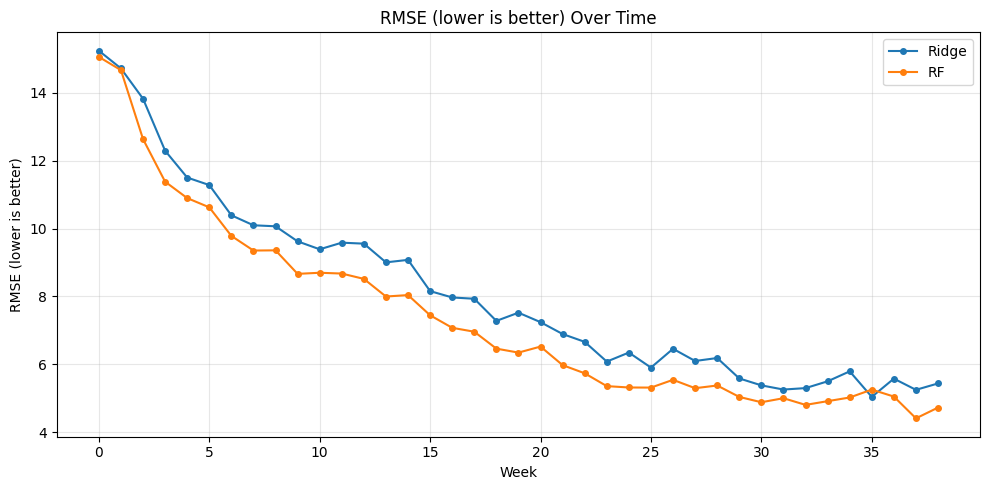

Saved: ../reports/figures/regression_r2_over_time.png


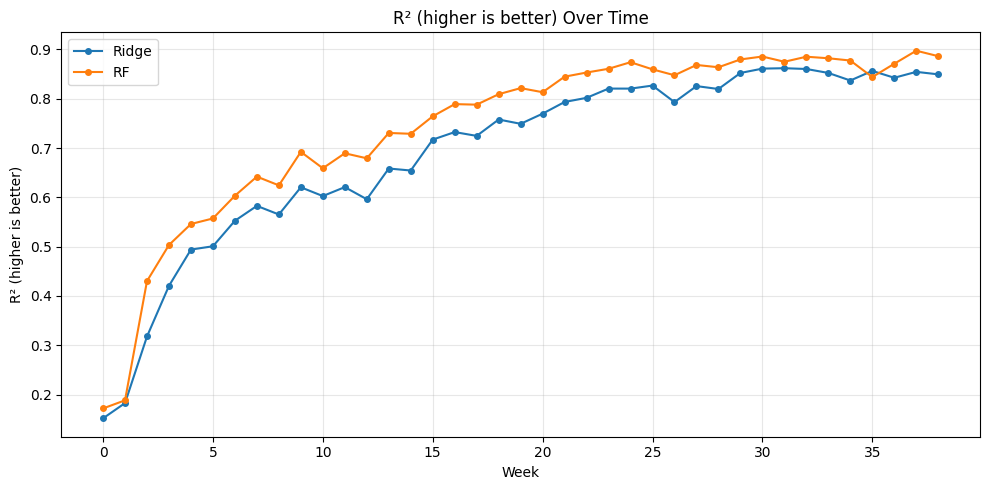

In [25]:
def plot_metric(metric, ylabel=None, save=True):
    """Plot a metric over weeks for all models."""
    fig, ax = plt.subplots(figsize=(10, 5))
    for name, dfm in all_results.items():
        ax.plot(dfm["week"], dfm[metric], marker="o", label=name, markersize=4)
    ax.set_xlabel("Week")
    ax.set_ylabel(ylabel or metric.upper())
    ax.set_title(f"{ylabel or metric.upper()} Over Time")
    ax.legend()
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    
    if save:
        filepath = FIG_DIR / f"regression_{metric}_over_time.png"
        fig.savefig(filepath, dpi=150, bbox_inches="tight")
        print(f"Saved: {filepath}")
    plt.show()

plot_metric("rmse", "RMSE (lower is better)")
plot_metric("r2", "R² (higher is better)")

### 6.2 Predicted vs Actual Scores

Scatter plots showing model predictions against actual scores for each week. The closer points are to the diagonal "Ideal" line, the better the predictions.

NameError: name 'PVA_DIR' is not defined

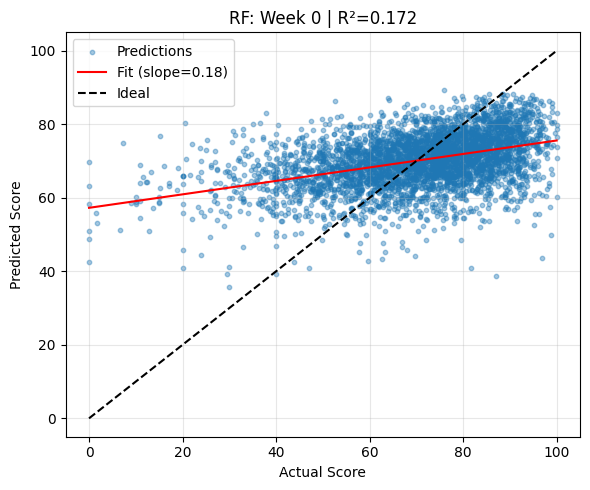

In [26]:
# Save predicted vs actual plots for key milestone weeks
milestone_weeks = [0, 5, 10, 15, 20, 25, 30, 35, max(weeks)]
milestone_weeks = sorted(set(w for w in milestone_weeks if w in weeks))

for t in milestone_weeks:
    out = fit_eval_regressor_one_week(df, t, REG_TARGET, drop_cols, KEYS, models["RF"])
    if out is None:
        continue

    y, p = out["y_test"], out["pred"]
    
    # Fit regression line
    a, b = np.polyfit(y, p, 1)
    x_line = np.linspace(y.min(), y.max(), 100)

    fig, ax = plt.subplots(figsize=(6, 5))
    ax.scatter(y, p, alpha=0.4, s=10, label="Predictions")
    ax.plot(x_line, a * x_line + b, "r-", label=f"Fit (slope={a:.2f})")
    ax.plot(x_line, x_line, "k--", label="Ideal")
    ax.set_xlabel("Actual Score")
    ax.set_ylabel("Predicted Score")
    ax.set_title(f"RF: Week {t} | R²={out['r2']:.3f}")
    ax.legend(loc="upper left")
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    
    filepath = PVA_DIR / f"regression_pred_vs_actual_week{t:02d}.png"
    fig.savefig(filepath, dpi=150, bbox_inches="tight")
    print(f"Saved: {filepath}")
    plt.show()

---

## 7. Feature Importance <a id="7-importance"></a>

Extract feature importances from the Random Forest model to understand which variables drive predictions most strongly.

In [ ]:
# Loop every 5th week
weeks_set = set(df["week"].unique())
top_n = 15
all_importances = []

for selected_week in range(0, max(weeks_set) + 1, 5):
    if selected_week not in weeks_set:
        continue

    out_rf = fit_eval_regressor_one_week(
        df, selected_week, REG_TARGET, drop_cols, KEYS, models["RF"]
    )

    prep = out_rf["pipe"].named_steps["prep"]
    rf = out_rf["pipe"].named_steps["model"]
    features = prep.get_feature_names_out()
    importances = rf.feature_importances_

    importance_df = (
        pd.DataFrame({"feature": features, "importance": importances})
        .sort_values("importance", ascending=False)
    )
    all_importances.append(
        importance_df.assign(week=selected_week)
    )

    # Plot (top 15)
    top_features = importance_df.head(top_n)
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.barh(range(top_n), top_features["importance"].values[::-1], color="steelblue")
    ax.set_yticks(range(top_n))
    ax.set_yticklabels(top_features["feature"].values[::-1])
    ax.set_xlabel("Importance")
    ax.set_title(f"Top {top_n} Feature Importances (RF, Week {selected_week})")
    ax.grid(True, alpha=0.3, axis="x")
    plt.tight_layout()

    filepath = FI_DIR / f"regression_feature_importance_week_{selected_week}.png"
    fig.savefig(filepath, dpi=150, bbox_inches="tight")
    plt.show()

# Save combined CSV
fi_all = pd.concat(all_importances, ignore_index=True)
csv_path = GAINS_DIR / "feature_importance_gains_all_weeks.csv"
fi_all.to_csv(csv_path, index=False)
print(f"Saved: {csv_path}")


---

## Feature importance over time

In [ ]:
# Find repo root by walking up from CWD
root = Path.cwd()
target = Path("reports/feature_importance_gains/feature_importance_gains_all_weeks.csv")
while root != root.parent and not (root / target).exists():
    root = root.parent

if not (root / target).exists():
    raise FileNotFoundError(f"Could not find {target} starting from {Path.cwd()}")

df_fi = pd.read_csv(root / target)

top_k = 5
top_features = (
    df_fi.groupby("feature")["importance"]
    .mean()
    .sort_values(ascending=False)
    .head(top_k)
    .index
)

pivot = (
    df_fi[df_fi["feature"].isin(top_features)]
    .pivot_table(index="week", columns="feature", values="importance", aggfunc="mean")
    .sort_index()
)

fig, ax = plt.subplots(figsize=(10, 6))
pivot.plot(ax=ax, marker="o")
ax.set_xlabel("Week")
ax.set_ylabel("Importance")
ax.set_title(f"Top {top_k} Feature Importances Over Time")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# If loading from CSV on disk:
# df_fi = pd.read_csv("path/to/feature_importance_gains_all_weeks.csv")

df_fi = fi_all  # or use your dataframe variable

# pick top features by average importance across weeks
top_k = 10
top_features = (
    df_fi.groupby("feature")["importance"]
    .mean()
    .sort_values(ascending=False)
    .head(top_k)
    .index
)

plot_df = df_fi[df_fi["feature"].isin(top_features)]

# pivot to week x feature
pivot = plot_df.pivot_table(
    index="week", columns="feature", values="importance", aggfunc="mean"
).sort_index()

fig, ax = plt.subplots(figsize=(10, 6))
pivot.plot(ax=ax, marker="o")
ax.set_xlabel("Week")
ax.set_ylabel("Importance")
ax.set_title(f"Top {top_k} Feature Importances Over Time")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


---

## Summary

**Key Findings:**
- **Prediction improves with time**: R² increases from ~0.18 (week 0) to ~0.89 (week 38) as more behavioral data accumulates
- **Random Forest outperforms Ridge**: RF captures non-linear relationships, especially in later weeks
- **Assessment features dominate**: `cumulative_weighted_score_assess` and `max_possible_final_score_assess` are the top predictors
- **VLE engagement matters**: Forum, content, and quiz clicks contribute meaningfully to predictions